<a href="https://colab.research.google.com/github/VDJ2824/glaucoma_detection/blob/main/notebooks/01_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — ACRIMA dataset exploration

Read-only exploration of original images using `glaucoma.data.exploration` and the existing adapter/validation utilities. No splitting, augmentation, deduplication-on-disk or model training occurs. Run notebook 00 first, set the dataset root to the actual flat image directory, and refresh its saved session after changing YAML. Real data remains on your configured storage; this repository contains no images.

## Provenance and labels
The [original ACRIMA paper](https://doi.org/10.1186/s12938-019-0649-y) confirms 705 images: 396 glaucoma and 309 normal. For the inspected flat release, canonical filenames are `Im<number>_g_ACRIMA.jpg` → 1 and `Im<number>_ACRIMA.jpg` → 0, case-insensitive. See [verification details](../docs/datasets.md#filename-label-mode-and-provenance) for source limitations. Number strings are image IDs, never patient IDs. Unknown names fail explicitly. Folder/CSV modes remain available; do not reinterpret diabetic-retinopathy annotations.

## Load notebook 00 session
Paste its printed SESSION_FILE below when using another kernel. Ensure `label_mode: filename` in the refreshed session for your flat download.

In [1]:
from google.colab import drive
from pathlib import Path
import sys
import os

drive.mount("/content/drive")

REPO_DIR = Path("/content/glaucoma_detection")

if not REPO_DIR.exists():
    !git clone https://github.com/VDJ2824/glaucoma_detection.git /content/glaucoma_detection
else:
    !git -C /content/glaucoma_detection pull --ff-only origin main

os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR / "src"))

Mounted at /content/drive
Cloning into '/content/glaucoma_detection'...
remote: Enumerating objects: 208, done.
remote: Counting objects: 100% (208/208), done.
remote: Compressing objects: 100% (167/167), done.
remote: Total 208 (delta 48), reused 77 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (208/208), 90.10 KiB | 4.09 MiB/s, done.
Resolving deltas: 100% (48/48), done.


In [2]:
from pathlib import Path
import os
import sys

from google.colab import drive
drive.mount("/content/drive")

REPO_DIR = Path("/content/glaucoma_detection")

if not REPO_DIR.exists():
    !git clone https://github.com/VDJ2824/glaucoma_detection.git /content/glaucoma_detection

os.chdir(REPO_DIR)

sys.path.insert(0, str(REPO_DIR / "src"))

from glaucoma.utils.notebook_runtime import load_session

SESSION_FILE = "/content/drive/MyDrive/glaucoma_detection/artifacts/runs/development/environment/session.json"

cfg = load_session(SESSION_FILE)

print("Dataset:", cfg["datasets"][cfg["datasets"]["selected"]]["root"])
print("Run artifacts:", cfg["artifacts"]["root"])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database
Run artifacts: /content/drive/MyDrive/glaucoma_detection/artifacts/runs/development


In [3]:
from glaucoma.data.exploration import explore_dataset, plot_class_distribution, plot_samples
import matplotlib.pyplot as plt


## Discover originals and run duplicate/corruption checks
The shared helper calls the selected adapter and `validate_metadata` with strict duplicate reporting. It retains all original rows for class counts. A duplicate is reported, not removed; invalid/corrupt files are excluded only from dimension measurements and previews. This is an audit, not the preparation/splitting pipeline.

In [9]:
from pathlib import Path

image_dir = Path(cfg["datasets"]["acrima"]["root"])

print("Folder exists:", image_dir.exists())
print("Total images:", sum(
    p.is_file() and p.suffix.lower() == ".jpg"
    for p in image_dir.iterdir()
))

cfg["datasets"]["acrima"]["root"] = str(image_dir)

print(cfg["datasets"]["acrima"]["root"])

Folder exists: True
Total images: 705
/content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database


In [10]:
exploration = explore_dataset(cfg)
print(f"Original image rows: {len(exploration.metadata)}")
print(exploration.metadata.head().to_string(index=False))
print(f"Available patient IDs: {exploration.metadata.patient_id.ne('').sum()}")
print("Image numbers are not patient IDs; unknown IDs remain blank.")


Original image rows: 705
        image_id                                                                          image_path dataset_name patient_id  label split
Im001_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im001_ACRIMA.jpg       acrima                 0      
Im002_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im002_ACRIMA.jpg       acrima                 0      
Im003_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im003_ACRIMA.jpg       acrima                 0      
Im004_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im004_ACRIMA.jpg       acrima                 0      
Im005_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im005_ACRIMA.jpg       acrima                 0      
Available patient IDs: 0
Image numbers are not patient IDs; unknown IDs remain blank.


## Class distribution
Counts and percentages are computed from discovered originals, before any future deduplication. The inspected full dataset reference is 309 label-0 and 396 label-1 images. These reference counts are not used to assign labels or fill missing data; smaller subsets are allowed.

 label   class_name  count  percentage
     0 non_glaucoma    309   43.829787
     1     glaucoma    396   56.170213
Full-release reference from the original paper: 705 total; label 0: 309; label 1: 396.


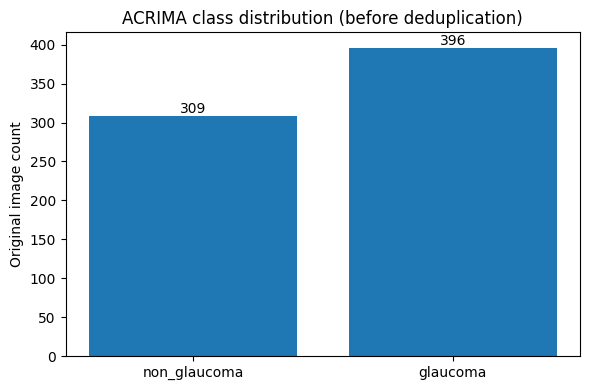

In [11]:
print(exploration.class_distribution.to_string(index=False))
print("Full-release reference from the original paper: 705 total; label 0: 309; label 1: 396.")
class_figure = plot_class_distribution(exploration)
plt.show()


## Image dimensions and aspect ratios
Measure decoded original width/height and aspect ratio without resizing, normalization or augmentation. Corrupt and invalid paths are excluded; counts in this table can be smaller than the discovered total. Statistics include count, mean, standard deviation, min, quartiles and max.

In [12]:
print(f"Decoded images measured: {len(exploration.dimensions)}")
print(exploration.dimension_statistics.to_string())
print(exploration.dimensions.head().to_string(index=False))


Decoded images measured: 705
             width       height  aspect_ratio
count   705.000000   705.000000    705.000000
mean    529.719149   529.009929      1.001142
std     243.509685   243.053518      0.013445
min     178.000000   178.000000      1.000000
25%     340.000000   340.000000      1.000000
50%     424.000000   421.000000      1.000000
75%     718.000000   712.000000      1.000000
max    1420.000000  1420.000000      1.300336
        image_id                                                                          image_path  label  width  height  aspect_ratio
Im001_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im001_ACRIMA.jpg      0    349     349           1.0
Im002_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im002_ACRIMA.jpg      0    277     277           1.0
Im003_ACRIMA.jpg /content/drive/MyDrive/glaucoma_detection/data/raw/ACRIMA/database/Im003_ACRIMA.jpg      0    409     409           1.0
Im004_ACR

## Sample image visualization
Show a reproducible sample from each class in RGB at original decoded dimensions. No image is written, resized or changed. Missing valid examples are marked rather than fabricated. Do not publish notebook outputs containing retinal images or private paths.

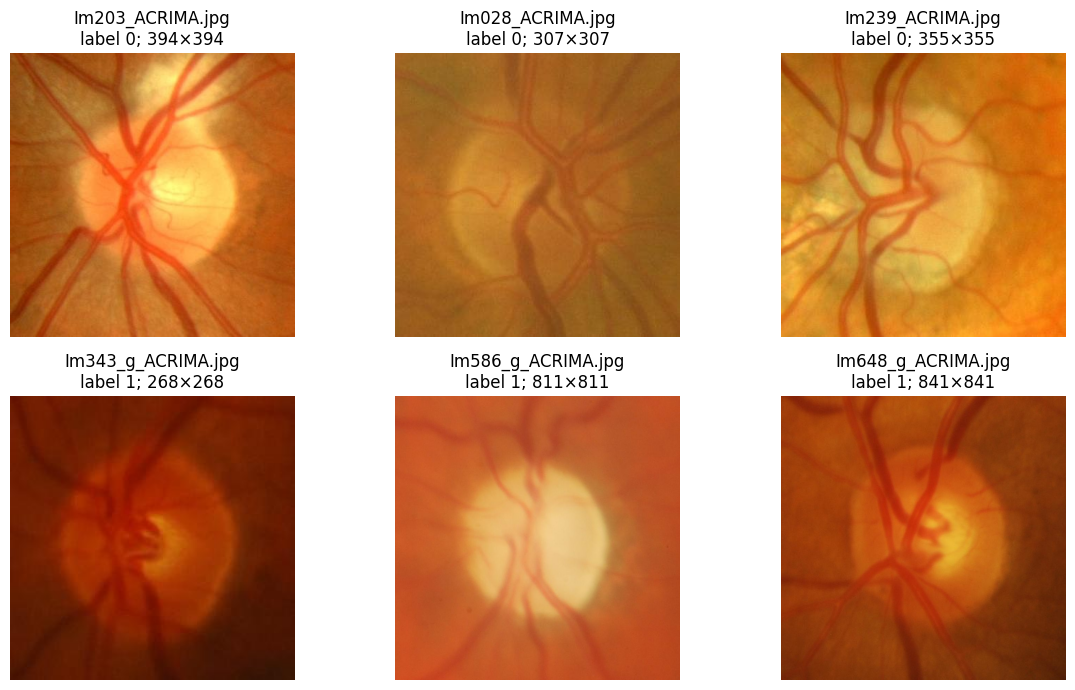

In [13]:
sample_figure = plot_samples(exploration, per_class=3, seed=cfg["seed"])
plt.show()


## Review validation findings
Identical decoded pixels, conflicting labels/grouping, corrupt images and invalid paths are reported by the existing validator. Decoded-pixel hashing does not detect every resized, cropped or differently compressed near-duplicate. Resolve errors before any future split. Counts matching 705 alone do not prove data integrity.

In [14]:
issues = exploration.validation.issues
if issues.empty:
    print("No metadata/path/corruption/exact-duplicate issues detected.")
else:
    print(issues.to_string(index=False))
    print(issues.groupby(["severity", "code"]).size().to_string())
    print("Validation errors present:", bool(exploration.validation.has_errors))
print("Exploration finished without splitting, training or altering originals.")


No metadata/path/corruption/exact-duplicate issues detected.
Exploration finished without splitting, training or altering originals.


## Optional persistent analytical summaries
Disabled by default. If enabled, save only derived CSV summaries under the configured run's metrics directory, which notebook 00 places on Drive (or Kaggle working storage). Filenames/paths in validation details are private; keep these artifacts out of Git. No images, split manifests or model artifacts are generated.

In [15]:
SAVE_SUMMARIES = False
if SAVE_SUMMARIES:
    summary_dir = Path(cfg["artifacts"]["metrics"]) / "exploration"
    summary_dir.mkdir(parents=True, exist_ok=True)
    exploration.class_distribution.to_csv(summary_dir / "class_distribution.csv", index=False)
    exploration.dimension_statistics.to_csv(summary_dir / "dimension_statistics.csv")
    exploration.dimensions.to_csv(summary_dir / "image_dimensions.csv", index=False)
    exploration.validation.issues.to_csv(summary_dir / "validation_issues.csv", index=False)
    print("Saved analytical CSVs to", summary_dir)
else:
    print("Summary export disabled; exploration wrote no dataset or report files.")


Summary export disabled; exploration wrote no dataset or report files.
